# Step 3 — Will this game still have players in 6–12 months?

**Research question.** Given 90 days of Steam player counts, Twitch attention and store metadata, can we predict whether a game will still average **at least 10 concurrent players** 6–12 months later?

**Who it is for.** Publishers and portfolio managers who run a catalogue of live games. They must decide which titles still deserve updates, community management, marketing or server spend, and which are quietly emptying.

**How this notebook is organised**

1. Load the daily panel, store metadata and Twitch data.
2. Build a feature/target dataset for any *origin date*: features from the 90 days after the origin, target from days 180–365 after it.
3. Explore how retention differs by business model, genre and Twitch attention.
4. Compare models against honest baselines. This uses publisher-grouped cross-validation on the first origin (Dec 2017), then a true **out-of-time backtest**: train on Dec 2017 data, predict Feb 2019 → Jan 2020.
5. Feature-group ablation (does Twitch add anything?), importance, threshold sensitivity, young-game check, regression.
6. Deliverables: a backtested risk-tier table and a forward forecast for H2 2020.

**Important framing.** The Steam histories cover **14 Dec 2017 – 12 Aug 2020** for about 2,000 games that were mostly already on sale (median age at the start: 2 years). This is therefore mainly a *catalogue-monitoring* model for live games. Section 7 checks separately how it behaves on the 79 games released at most 45 days before tracking began.

In [1]:
from pathlib import Path
import csv
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
STEAM_DIR = PROJECT_ROOT / "data" / "steam-games-dataset"
SULLY_DIR = PROJECT_ROOT / "data" / "sullygnome"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_DAYS = 90            # features: days [origin, origin + 90)
TARGET_START, TARGET_END = 180, 365   # target: days [origin + 180, origin + 365]
MIN_FEATURE_DAYS = 60        # a game needs at least 60 observed feature days...
MIN_TARGET_DAYS = 150        # ...and 150 observed target days
THRESHOLD = 10               # "retained" = mean concurrent players in the target window >= 10
RANDOM_STATE = 42

ORIGINS = {
    "train": pd.Timestamp("2017-12-14"),       # target ends 2018-12-14
    "train_2": pd.Timestamp("2018-06-14"),     # target ends 2019-06-14 (used for the 2020 robustness check)
    "test": pd.Timestamp("2019-02-01"),        # target 2019-07-31 .. 2020-01-31: pre-COVID backtest
    "test_covid": pd.Timestamp("2019-08-01"),  # target 2020-01-28 .. 2020-07-30: lockdown period
}

COLORS = {"retained": "#2a7ab9", "at_risk": "#d1495b", "neutral": "#8c8c8c", "accent": "#edae49", "dark": "#30343f"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})


def save(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png")
    print(f"Saved reports/figures/{name}.png")

## 1. Load data

In [2]:
panel = pd.read_parquet(PROCESSED_DIR / "steam_daily_panel.parquet",
                        columns=["appid", "date", "mean_player_count", "median_player_count", "max_player_count"])
summary = pd.read_csv(PROCESSED_DIR / "steam_game_summary.csv",
                      parse_dates=["first_observed", "last_observed", "releasedate"])
twitch = pd.read_csv(SULLY_DIR / "twitch_monthly_by_appid.csv")
twitch["month"] = pd.PeriodIndex(twitch["month"], freq="M")
twitch_mapped_ids = set(pd.read_csv(SULLY_DIR / "appid_map_validated.csv")["appid"])
DATA_END = panel["date"].max()

for name, origin in ORIGINS.items():
    assert origin + pd.Timedelta(days=TARGET_END) <= DATA_END, f"{name} target window runs past the data"

print(f"Daily panel: {len(panel):,} rows, {panel['appid'].nunique():,} apps, "
      f"{panel['date'].min().date()} to {DATA_END.date()}")
print("App types:", summary["type"].fillna("missing").value_counts().to_dict())

Daily panel: 1,939,902 rows, 1,998 apps, 2017-12-14 to 2020-08-12
App types: {'game': 1851, 'missing': 111, 'demo': 13, 'advertising': 12, 'mod': 8, 'dlc': 3}


In [3]:
def read_multi(filename, value_name):
    """Read the wide 'appid,value1,value2,...' files. csv.reader keeps quoted names like "Psyonix, Inc." intact."""
    rows = []
    with (STEAM_DIR / filename).open(encoding="cp1252", newline="") as file:
        for record in csv.reader(file):
            values = [value.strip() for value in record if value.strip()]
            if len(values) > 1 and values[0].isdigit():
                rows.extend((int(values[0]), value) for value in values[1:])
    return pd.DataFrame(rows, columns=["appid", value_name]).drop_duplicates()


genres = read_multi("applicationGenres.csv", "genre")
tags = read_multi("applicationTags.csv", "tag")
languages = read_multi("applicationSupportedlanguages.csv", "language")
packages = read_multi("applicationPackages.csv", "package")
developers = read_multi("applicationDevelopers.csv", "developer")
publishers = read_multi("applicationPublishers.csv", "publisher")

# Keep real games only: demos, mods, DLC, test servers and adverts are not products to retain players for.
games = summary[summary["type"].eq("game")].copy()
print(f"Games kept: {len(games):,} of {len(summary):,} apps")

Games kept: 1,851 of 1,998 apps


### Static game features

The old notebook took the first genre in each list as the "primary genre". The source lists genres **alphabetically**, so that column was really "alphabetically first genre": 889 games were labelled *Action*. Every genre now gets its own 0/1 column. Tags, languages, packages, developers and publishers were loaded before but never used; they are now included.

In [4]:
def multi_hot(long, column, min_games, prefix, top=None):
    long = long[long["appid"].isin(games["appid"])]
    counts = long[column].value_counts()
    keep = counts[counts >= min_games].index
    if top:
        keep = keep[:top]
    wide = pd.crosstab(long["appid"], long[column]).reindex(columns=keep).clip(upper=1)
    wide.columns = [f"{prefix}{value.lower().replace(' ', '_').replace('-', '_')}" for value in wide.columns]
    return wide


genre_onehot = multi_hot(genres, "genre", 25, "genre_")
tag_onehot = multi_hot(tags, "tag", 100, "tag_", top=20)
GENRE_COLUMNS, TAG_COLUMNS = list(genre_onehot.columns), list(tag_onehot.columns)

main_publisher = publishers.groupby("appid")["publisher"].first()
publisher_size = main_publisher.map(main_publisher[main_publisher.index.isin(games["appid"])].value_counts())

static = (
    games[["appid", "name", "releasedate", "freetoplay"]].set_index("appid")
    .join(genre_onehot).join(tag_onehot)
    .join(tags.groupby("appid").size().rename("n_tags"))
    .join(languages.groupby("appid").size().rename("n_languages"))
    .join(packages.groupby("appid").size().rename("n_packages"))
    .join(developers.groupby("appid").size().rename("n_developers"))
    .join(main_publisher.rename("publisher"))
    .join(np.log1p(publisher_size).rename("log_publisher_catalog"))
)
static[GENRE_COLUMNS + TAG_COLUMNS] = static[GENRE_COLUMNS + TAG_COLUMNS].fillna(0)
static["freetoplay_unknown"] = static["freetoplay"].isna().astype(int)
static["twitch_mapped"] = static.index.isin(twitch_mapped_ids).astype(int)
# Group id for cross-validation: games from one publisher never sit on both sides of a split.
static["group"] = static["publisher"].fillna(pd.Series("appid_" + static.index.astype(str), index=static.index))
print(f"Static features: {len(GENRE_COLUMNS)} genres, {len(TAG_COLUMNS)} tags, plus counts and publisher size")

Static features: 12 genres, 20 tags, plus counts and publisher size


## 2. Features and target for any origin date

For an origin date *t*:

- **Steam features** use days *t* … *t*+89 only: level (log mean players), peak-to-mean ratio, volatility, trend (slope of log players per 30 days), change from the first to the last month, weekend uplift, share of near-empty days and the lowest day.
- **Twitch features** use the calendar months overlapping that window: average and peak viewers, watch time, channels, months in the top 2,000, and viewers per Steam player. Unmapped games are flagged rather than imputed.
- **Metadata**: age at *t*, Early Access (store release date still in the future), free-to-play, genres, top tags, counts of languages / packages / developers, publisher catalogue size.
- **Target**: mean daily players over days *t*+180 … *t*+365 (at least 150 observed days). It is never touched by the features, leaving a 90-day gap between the two windows.

In [5]:
STEAM_FEATURES = ["log_early_mean", "log_peak_to_mean", "volatility", "trend_log_per_30d",
                  "last_vs_first_month", "weekend_uplift", "low_day_share", "log_early_min"]
TWITCH_FEATURES = ["log_twitch_avg_viewers", "log_twitch_peak_viewers", "log_twitch_view_minutes",
                   "log_twitch_avg_channels", "twitch_months_in_top", "twitch_viewers_per_player", "twitch_mapped"]
META_FEATURES = (["age_years", "early_access", "release_unknown", "freetoplay", "freetoplay_unknown",
                  "n_tags", "n_languages", "n_packages", "n_developers", "log_publisher_catalog"]
                 + GENRE_COLUMNS + TAG_COLUMNS)
ALL_FEATURES = META_FEATURES + STEAM_FEATURES + TWITCH_FEATURES
FEATURE_GROUPS = {"Metadata": META_FEATURES, "Steam activity": STEAM_FEATURES, "Twitch": TWITCH_FEATURES}


def steam_window_features(origin):
    window = panel[(panel["date"] >= origin) & (panel["date"] < origin + pd.Timedelta(days=FEATURE_DAYS))].copy()
    window["t"] = (window["date"] - origin).dt.days
    window["y"] = np.log1p(window["mean_player_count"])
    window["ty"], window["tt"] = window["t"] * window["y"], window["t"] ** 2
    window["weekend"] = window["date"].dt.dayofweek >= 5
    grouped = window.groupby("appid")
    out = grouped.agg(feature_days=("date", "nunique"), early_mean=("mean_player_count", "mean"),
                      early_std=("mean_player_count", "std"), early_peak=("max_player_count", "max"),
                      early_min=("mean_player_count", "min"),
                      low_day_share=("median_player_count", lambda values: values.le(1).mean()),
                      t=("t", "mean"), y=("y", "mean"), ty=("ty", "mean"), tt=("tt", "mean"))
    out["log_early_mean"] = np.log1p(out["early_mean"])
    out["log_peak_to_mean"] = np.log1p(out["early_peak"]) - out["log_early_mean"]
    out["volatility"] = out["early_std"] / (out["early_mean"] + 1)
    out["trend_log_per_30d"] = 30 * (out["ty"] - out["t"] * out["y"]) / (out["tt"] - out["t"] ** 2)
    first = window[window["t"] < 30].groupby("appid")["y"].mean()
    last = window[window["t"] >= FEATURE_DAYS - 30].groupby("appid")["y"].mean()
    out["last_vs_first_month"] = last - first
    weekend = window.groupby(["appid", "weekend"])["y"].mean().unstack()
    out["weekend_uplift"] = weekend.get(True) - weekend.get(False)
    out["log_early_min"] = np.log1p(out["early_min"])
    return out[["feature_days", "early_mean"] + STEAM_FEATURES]


def twitch_window_features(origin):
    months = pd.period_range(origin.to_period("M"), (origin + pd.Timedelta(days=FEATURE_DAYS - 1)).to_period("M"))
    window = twitch[twitch["month"].isin(months)]
    grouped = window.groupby("appid")
    out = pd.DataFrame({
        # Months outside the top 2,000 count as 0, so sums are divided by the number of months in the window.
        "avg_viewers": grouped["avgviewers"].sum() / len(months),
        "peak_viewers": grouped["maxviewers"].max(),
        "view_minutes": grouped["viewminutes"].sum(),
        "avg_channels": grouped["avgchannels"].sum() / len(months),
        "twitch_months_in_top": grouped["month"].nunique(),
    })
    return pd.DataFrame({
        "log_twitch_avg_viewers": np.log1p(out["avg_viewers"]),
        "log_twitch_peak_viewers": np.log1p(out["peak_viewers"]),
        "log_twitch_view_minutes": np.log1p(out["view_minutes"]),
        "log_twitch_avg_channels": np.log1p(out["avg_channels"]),
        "twitch_months_in_top": out["twitch_months_in_top"],
    })


def target_window(origin):
    window = panel[panel["date"].between(origin + pd.Timedelta(days=TARGET_START), origin + pd.Timedelta(days=TARGET_END))]
    return window.groupby("appid").agg(future_mean=("mean_player_count", "mean"), target_days=("date", "nunique"))


def build_dataset(origin, labelled=True):
    data = static.join(steam_window_features(origin), how="inner").join(twitch_window_features(origin))
    twitch_columns = [c for c in TWITCH_FEATURES if c not in ("twitch_viewers_per_player", "twitch_mapped")]
    data[twitch_columns] = data[twitch_columns].fillna(0)
    data["twitch_viewers_per_player"] = data["log_twitch_avg_viewers"] - data["log_early_mean"]
    data["age_years"] = (origin - data["releasedate"]).dt.days / 365.25
    data["early_access"] = (data["age_years"] < 0).astype(int)
    data["release_unknown"] = data["releasedate"].isna().astype(int)
    data["age_years"] = data["age_years"].clip(lower=0)
    data = data[data["feature_days"] >= MIN_FEATURE_DAYS]
    if labelled:
        data = data.join(target_window(origin), how="inner")
        data = data[data["target_days"] >= MIN_TARGET_DAYS]
        data["retained"] = data["future_mean"].ge(THRESHOLD).astype(int)
    data["origin"] = origin
    return data


datasets = {name: build_dataset(origin) for name, origin in ORIGINS.items()}
coverage = pd.DataFrame({
    name: {"origin": ORIGINS[name].date(), "games": len(d), "retention_rate": round(d["retained"].mean(), 3),
           "with_twitch_in_window": int((d["twitch_months_in_top"] > 0).sum())}
    for name, d in datasets.items()
}).T
display(coverage)
train, test = datasets["train"], datasets["test"]

,origin,games,retention_rate,with_twitch_in_window
train,2017-12-14,1850,0.874,859
train_2,2018-06-14,1850,0.852,814
test,2019-02-01,1851,0.834,721
test_covid,2019-08-01,1851,0.862,627


Roughly one game in eight drops below 10 average players, so the classes are imbalanced. Accuracy alone would reward a model that always says "retained". The metrics below are therefore **ROC-AUC**, **balanced accuracy** and the **precision/recall of the "at risk" class**.

## 3. Exploratory analysis (Dec 2017 origin)

Saved reports/figures/fig01_early_vs_future.png


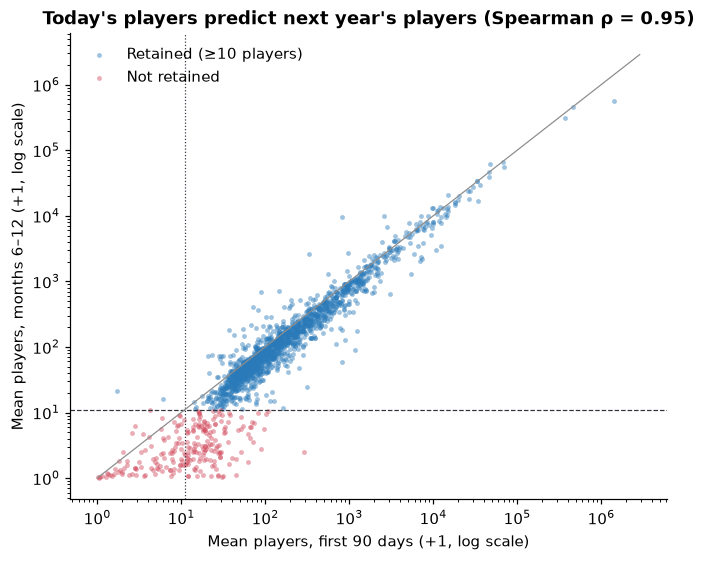

In [6]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for label, color, name in [(1, COLORS["retained"], "Retained (≥10 players)"), (0, COLORS["at_risk"], "Not retained")]:
    subset = train[train["retained"] == label]
    ax.scatter(subset["early_mean"] + 1, subset["future_mean"] + 1, s=10, alpha=0.45, color=color, label=name, linewidths=0)
ax.set(xscale="log", yscale="log", xlabel="Mean players, first 90 days (+1, log scale)",
       ylabel="Mean players, months 6–12 (+1, log scale)")
ax.axhline(THRESHOLD + 1, color=COLORS["dark"], lw=0.8, ls="--")
ax.axvline(THRESHOLD + 1, color=COLORS["dark"], lw=0.8, ls=":")
lims = [1, train[["early_mean", "future_mean"]].max().max() * 2]
ax.plot(lims, lims, color=COLORS["neutral"], lw=0.8)
rho = train[["early_mean", "future_mean"]].corr("spearman").iloc[0, 1]
ax.set_title(f"Today's players predict next year's players (Spearman ρ = {rho:.2f})")
ax.legend(frameon=False, loc="upper left")
save(fig, "fig01_early_vs_future")
plt.show()

Most games sit close to the diagonal: player counts are very persistent. The interesting cases sit near the 10-player lines. Games that start at 10–40 players can go either way, and that is where a model can add value over "look at today's number".

,group,games,retention_rate,ci_low,ci_high
0,Free to play,339,0.962,0.936,0.977
1,Paid,1502,0.855,0.836,0.872
0,"Not in Twitch top 2,000",991,0.785,0.758,0.810
1,< 10 viewers,333,0.946,0.916,0.966
2,10–100 viewers,361,0.992,0.976,0.997
3,> 100 viewers,165,1.000,0.977,1.000
0,Action,876,0.881,0.858,0.901
1,Indie,819,0.784,0.754,0.811
2,Adventure,553,0.857,0.826,0.884
3,Strategy,527,0.945,0.922,0.961


Saved reports/figures/fig02_retention_by_group.png


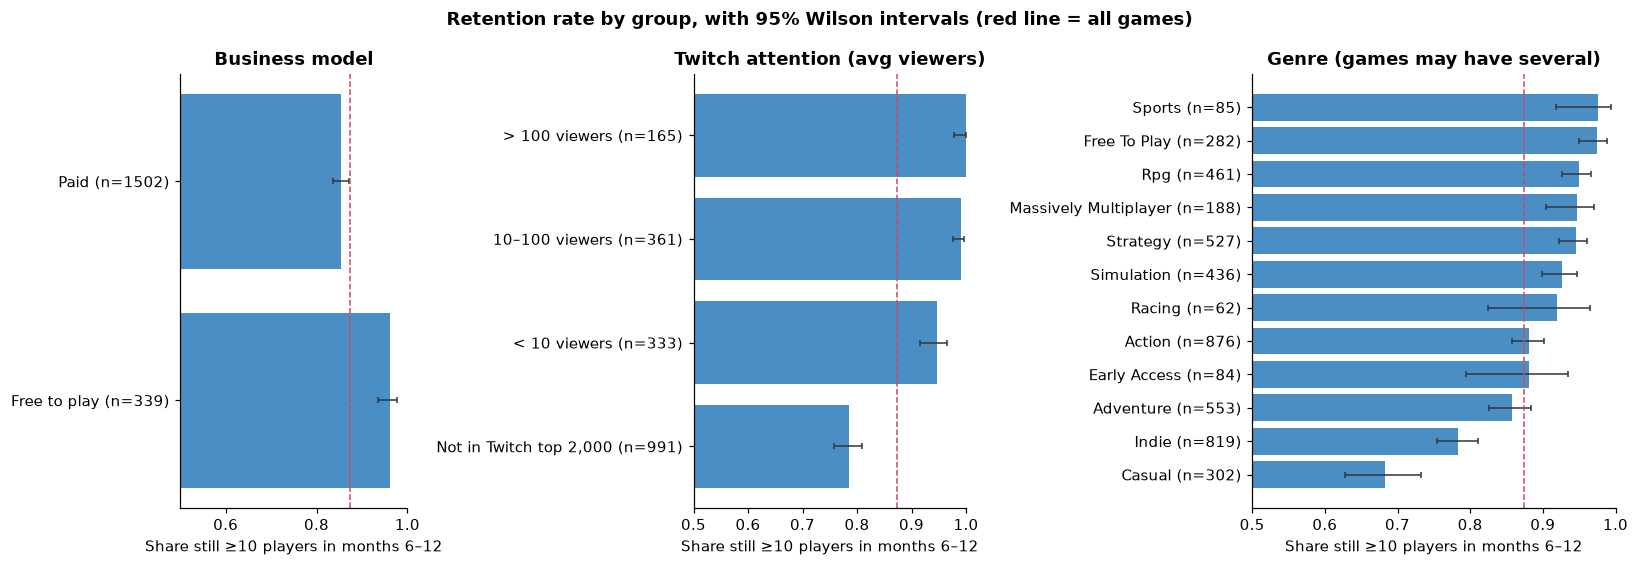

In [7]:
def wilson(successes, n, z=1.96):
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def rate_table(frame, masks):
    rows = []
    for label, mask in masks.items():
        n, k = int(mask.sum()), int(frame.loc[mask, "retained"].sum())
        low, high = wilson(k, n)
        rows.append({"group": label, "games": n, "retention_rate": k / n, "ci_low": low, "ci_high": high})
    return pd.DataFrame(rows)


business = rate_table(train, {"Free to play": train["freetoplay"].eq(1), "Paid": train["freetoplay"].eq(0)})
genre_rates = rate_table(train, {c.replace("genre_", "").replace("_", " ").title(): train[c].eq(1)
                                 for c in GENRE_COLUMNS if train[c].sum() >= 30})
twitch_tiers = pd.cut(train["log_twitch_avg_viewers"], [-0.1, 0, np.log1p(10), np.log1p(100), np.inf],
                      labels=["Not in Twitch top 2,000", "< 10 viewers", "10–100 viewers", "> 100 viewers"])
twitch_rates = rate_table(train, {str(level): twitch_tiers.eq(level) for level in twitch_tiers.cat.categories})
display(pd.concat([business, twitch_rates, genre_rates]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.2, 1.6]})
for ax, table, title in [(axes[0], business, "Business model"), (axes[1], twitch_rates, "Twitch attention (avg viewers)"),
                         (axes[2], genre_rates.sort_values("retention_rate"), "Genre (games may have several)")]:
    y = np.arange(len(table))
    ax.barh(y, table["retention_rate"], color=COLORS["retained"], alpha=0.85)
    ax.errorbar(table["retention_rate"], y, xerr=[table["retention_rate"] - table["ci_low"], table["ci_high"] - table["retention_rate"]],
                fmt="none", ecolor=COLORS["dark"], lw=1, capsize=2)
    ax.set_yticks(y, [f"{g} (n={n})" for g, n in zip(table["group"], table["games"])])
    ax.set_xlim(0.5, 1.0)
    ax.axvline(train["retained"].mean(), color=COLORS["at_risk"], ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("Share still ≥10 players in months 6–12")
fig.suptitle("Retention rate by group, with 95% Wilson intervals (red line = all games)", fontweight="bold")
fig.tight_layout()
save(fig, "fig02_retention_by_group")
plt.show()

- **Free-to-play** games retain more often than paid ones (96% vs 86%), and the 95% intervals do not overlap.
- **Twitch attention** shows the clearest gradient. Games with more than 100 average viewers almost never fall below 10 players. Twitch attention is, however, strongly tied to how many people already play (Section 5 tests whether it adds anything *beyond* Steam numbers).
- **Casual** and **Indie** games retain less often than Strategy, RPG or Simulation games. Genre differences are modest compared with the effect of current player levels.

## 4. Models vs. baselines

Candidates:

| Name | What it does |
|---|---|
| Always retained | Predicts every game survives (the old notebook's only baseline) |
| Rule: players ≥ 10 | Retained if the first-90-day mean is ≥ 10 players |
| Rule: tuned cut-off | Same single number, but the cut-off is learned on the training data to maximise balanced accuracy |
| Logistic regression | All features, standardised |
| Random forest | All features, 500 trees, balanced class weights |
| Gradient boosting | Histogram gradient boosting, balanced class weights |

**Validation 1 — grouped CV.** 5-fold cross-validation on the Dec 2017 origin, stratified by outcome and **grouped by publisher**. Sibling titles (e.g. several Football Manager editions) cannot leak between folds.

**Validation 2 — out-of-time backtest.** Fit on the Dec 2017 origin (outcomes known by Dec 2018). Predict games at the Feb 2019 origin, whose outcomes run Aug 2019 – Jan 2020. This replaces the old "chronological split", whose cut-off date was 14 Dec 2017: the old test set was just the 117 games whose first reading happened to be 4 days later.

In [8]:
class LevelRule:
    """Baseline: 'at risk' when 90-day mean players fall below a cut-off learned on the training data.

    predict_proba returns a logistic squash of the distance to the cut-off, so 0.5 sits exactly at the cut-off
    and ROC-AUC equals that of the raw player count.
    """

    def fit(self, X, y):
        level = np.log1p(np.asarray(X, dtype=float).ravel())
        y = np.asarray(y)
        candidates = np.unique(np.quantile(level, np.linspace(0.01, 0.6, 120)))
        scores = [balanced_accuracy_score(y, (level >= c).astype(int)) for c in candidates]
        self.cutoff_ = candidates[int(np.argmax(scores))]
        return self

    def predict_proba(self, X):
        level = np.log1p(np.asarray(X, dtype=float).ravel())
        p = 1 / (1 + np.exp(-4 * (level - self.cutoff_)))
        return np.column_stack([1 - p, p])


def make_model(kind, features=None):
    imputer = ("impute", SimpleImputer(strategy="median"))
    if kind == "Rule: tuned cut-off":
        return LevelRule()
    if kind == "Logistic regression":
        return Pipeline([imputer, ("scale", StandardScaler()),
                         ("model", LogisticRegression(C=0.3, max_iter=5000, class_weight="balanced"))])
    if kind == "Random forest":
        return Pipeline([imputer, ("model", RandomForestClassifier(
            n_estimators=500, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE))])
    if kind == "Gradient boosting":
        return Pipeline([imputer, ("model", HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=300, max_leaf_nodes=15, l2_regularization=1.0,
            class_weight="balanced", random_state=RANDOM_STATE))])
    raise ValueError(kind)


MODEL_FEATURES = {
    "Rule: tuned cut-off": ["early_mean"],
    "Logistic regression": ALL_FEATURES,
    "Random forest": ALL_FEATURES,
    "Gradient boosting": ALL_FEATURES,
}


def scores_for(name, fitted, frame):
    if name == "Always retained":
        return np.ones(len(frame))
    if name == "Rule: players ≥ 10":
        return frame["early_mean"].to_numpy()
    return fitted.predict_proba(frame[MODEL_FEATURES[name]])[:, 1]


def labels_for(name, scores):
    if name == "Always retained":
        return np.ones(len(scores), dtype=int)
    if name == "Rule: players ≥ 10":
        return (scores >= THRESHOLD).astype(int)
    return (scores >= 0.5).astype(int)


def metrics(y, scores, predicted):
    at_risk_true, at_risk_pred = 1 - y, 1 - predicted
    return {
        "roc_auc": roc_auc_score(y, scores) if len(np.unique(scores)) > 1 else 0.5,
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "at_risk_precision": precision_score(at_risk_true, at_risk_pred, zero_division=0),
        "at_risk_recall": recall_score(at_risk_true, at_risk_pred, zero_division=0),
        "at_risk_avg_precision": average_precision_score(at_risk_true, -scores) if len(np.unique(scores)) > 1 else at_risk_true.mean(),
    }


CANDIDATES = ["Always retained", "Rule: players ≥ 10"] + list(MODEL_FEATURES)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_train = train["retained"].to_numpy()
oof_scores = {name: np.zeros(len(train)) for name in CANDIDATES}
cv_rows = []
for fold, (fit_idx, val_idx) in enumerate(cv.split(train, y_train, groups=train["group"])):
    fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
    for name in CANDIDATES:
        fitted = None
        if name in MODEL_FEATURES:
            fitted = make_model(name).fit(fit_part[MODEL_FEATURES[name]], fit_part["retained"])
        scores = scores_for(name, fitted, val_part)
        oof_scores[name][val_idx] = scores
        cv_rows.append({"model": name, "fold": fold, **metrics(val_part["retained"].to_numpy(), scores, labels_for(name, scores))})

cv_results = pd.DataFrame(cv_rows).groupby("model", sort=False).agg(["mean", "std"]).drop(columns="fold")
display(cv_results.round(3))

roc_auc        balanced_accuracy        at_risk_precision        at_risk_recall        at_risk_avg_precision       
                       mean    std              mean    std              mean    std           mean    std                  mean    std
model                                                                                                                                  
Always retained       0.500  0.000             0.500  0.000             0.000  0.000          0.000  0.000                 0.126  0.001
Rule: players ≥ 10    0.967  0.018             0.691  0.033             0.983  0.039          0.384  0.068                 0.889  0.051
Rule: tuned cut-off   0.967  0.018             0.913  0.040             0.686  0.060          0.885  0.076                 0.889  0.051
Logistic regression   0.986  0.007             0.944  0.027             0.782  0.077          0.927  0.042                 0.920  0.040
Random forest         0.991  0.007             0.957  0.026             0.845  0.090          0.940  0.035                 0.954  0.032
Gradient boosting     0.990  0.007             0.945  0.029             0.853  0.105          0.915  0.042                 0.944  0.037

In [9]:
def bootstrap_ci(y, scores, predicted, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        draws.append(metrics(y[idx], scores[idx], predicted[idx]))
    draws = pd.DataFrame(draws)
    return draws.quantile(0.025), draws.quantile(0.975)


fitted_models = {name: make_model(name).fit(train[cols], train["retained"]) for name, cols in MODEL_FEATURES.items()}
y_test = test["retained"].to_numpy()
test_scores, test_rows = {}, []
for name in CANDIDATES:
    scores = scores_for(name, fitted_models.get(name), test)
    predicted = labels_for(name, scores)
    test_scores[name] = scores
    point = metrics(y_test, scores, predicted)
    low, high = bootstrap_ci(y_test, scores, predicted)
    test_rows.append({"model": name, **point, "auc_low": low["roc_auc"], "auc_high": high["roc_auc"],
                      "bal_acc_low": low["balanced_accuracy"], "bal_acc_high": high["balanced_accuracy"]})
test_results = pd.DataFrame(test_rows).set_index("model")
print(f"Out-of-time test: {len(test):,} games, {1 - y_test.mean():.1%} not retained")
display(test_results.round(3))

Out-of-time test: 1,851 games, 16.6% not retained


,roc_auc,balanced_accuracy,at_risk_precision,at_risk_recall,at_risk_avg_precision,auc_low,auc_high,bal_acc_low,bal_acc_high
model,,,,,,,,,
Always retained,0.500,0.500,0.000,0.000,0.166,0.500,0.500,0.500,0.500
Rule: players ≥ 10,0.982,0.927,0.914,0.870,0.935,0.973,0.989,0.908,0.946
Rule: tuned cut-off,0.982,0.908,0.542,0.980,0.935,0.973,0.989,0.896,0.920
Logistic regression,0.979,0.942,0.816,0.925,0.874,0.972,0.986,0.924,0.957
Random forest,0.982,0.957,0.870,0.941,0.867,0.975,0.988,0.943,0.971
Gradient boosting,0.983,0.961,0.840,0.958,0.881,0.974,0.990,0.948,0.972


### Where does the model beat the simple rule? Borderline games

For most games the answer is obvious from today's numbers: 5,000 players will not fall to under 10 within a year. The decision-relevant group is the **borderline** one, games averaging 5–50 players in the feature window.

In [10]:
borderline = test["early_mean"].between(5, 50).to_numpy()
borderline_rows = []
for name in ["Rule: players ≥ 10", "Rule: tuned cut-off", "Logistic regression", "Random forest", "Gradient boosting"]:
    scores = test_scores[name][borderline]
    predicted = labels_for(name, scores)
    low, high = bootstrap_ci(y_test[borderline], scores, predicted, n_boot=500)
    borderline_rows.append({"model": name, **metrics(y_test[borderline], scores, predicted),
                            "auc_low": low["roc_auc"], "auc_high": high["roc_auc"]})
borderline_results = pd.DataFrame(borderline_rows).set_index("model")
print(f"Borderline test games: {borderline.sum()} ({1 - y_test[borderline].mean():.0%} not retained)")
display(borderline_results.round(3))

Borderline test games: 537 (16% not retained)


,roc_auc,balanced_accuracy,at_risk_precision,at_risk_recall,at_risk_avg_precision,auc_low,auc_high
model,,,,,,,
Rule: players ≥ 10,0.931,0.783,0.907,0.576,0.813,0.900,0.958
Rule: tuned cut-off,0.931,0.729,0.262,0.976,0.813,0.900,0.958
Logistic regression,0.924,0.846,0.635,0.776,0.785,0.886,0.954
Random forest,0.961,0.894,0.772,0.835,0.819,0.940,0.976
Gradient boosting,0.961,0.905,0.694,0.882,0.786,0.942,0.977


**Reading the results.**

- *Ranking (ROC-AUC):* on the full test set every sensible method ties at about 0.98. Sorting games by today's player count already puts almost every fading game near the top.
- *Flagging (balanced accuracy):* the random forest is best (0.957 vs 0.927 for the "≥10 players" rule). It finds 94% of the games that were lost, against 87% for the rule, at a precision of 87%.
- *Stability:* in grouped CV on the 2018 period, the same "≥10 players" rule only reached a balanced accuracy of 0.69, because many games that later faded still had 10+ players in early 2018. The model held 0.95–0.96 in both periods. A fixed rule's quality depends on the market phase; the model's does not (see also 7b).
- *Tuning the rule's cut-off on 2018 data* (it picks ~32 players) makes it worse on 2019 (0.908). That is another sign that simple cut-offs do not transfer between periods.
- *Borderline games (5–50 players, 537 games):* the model clearly beats the rule (AUC 0.961 vs 0.931; it catches 84% vs 58% of the fading games).

Saved reports/figures/fig03_model_comparison.png


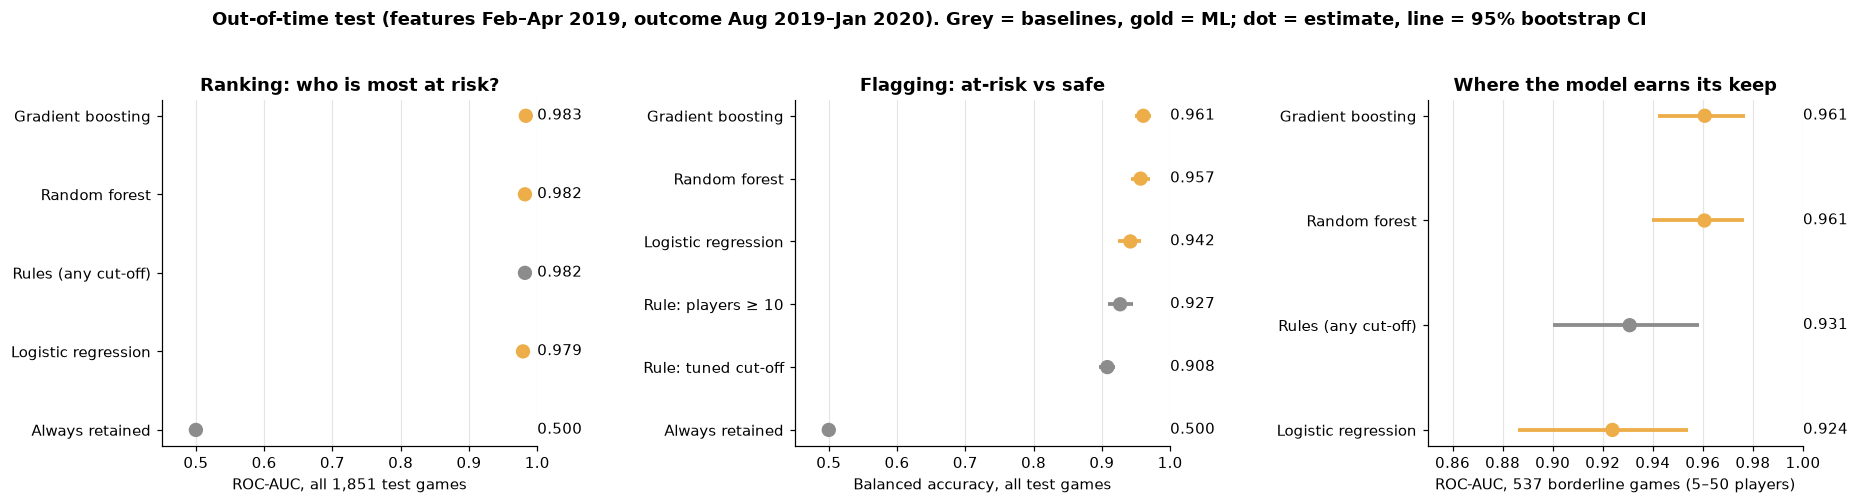

In [11]:
ML_MODELS = ["Logistic regression", "Random forest", "Gradient boosting"]
panels = [
    (test_results.drop(index="Rule: players ≥ 10"), "roc_auc", "auc_low", "auc_high", (0.45, 1.0),
     "ROC-AUC, all 1,851 test games", "Ranking: who is most at risk?"),
    (test_results, "balanced_accuracy", "bal_acc_low", "bal_acc_high", (0.45, 1.0),
     "Balanced accuracy, all test games", "Flagging: at-risk vs safe"),
    (borderline_results.drop(index="Rule: players ≥ 10"), "roc_auc", "auc_low", "auc_high", (0.85, 1.0),
     f"ROC-AUC, {borderline.sum()} borderline games (5–50 players)", "Where the model earns its keep"),
]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=False)
for ax, (table, column, low, high, xlim, xlabel, title) in zip(axes, panels):
    table = table.sort_values(column)
    y = np.arange(len(table))
    colors = [COLORS["accent"] if n in ML_MODELS else COLORS["neutral"] for n in table.index]
    ax.hlines(y, table[low], table[high], color=colors, lw=2.5)
    ax.scatter(table[column], y, color=colors, s=70, zorder=3)
    for yi, value in zip(y, table[column]):
        ax.text(1.0, yi, f"{value:.3f}", transform=ax.get_yaxis_transform(), va="center", ha="left", fontsize=9.5)
    ax.set_yticks(y, ["Rules (any cut-off)" if n == "Rule: tuned cut-off" and column == "roc_auc" else n for n in table.index])
    ax.set_xlim(*xlim)
    ax.grid(axis="x", color="#e5e5e5", lw=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
fig.suptitle("Out-of-time test (features Feb–Apr 2019, outcome Aug 2019–Jan 2020). Grey = baselines, gold = ML; dot = estimate, line = 95% bootstrap CI",
             fontweight="bold", y=1.03)
fig.tight_layout(w_pad=4)
save(fig, "fig03_model_comparison")
plt.show()

Model chosen by grouped CV: Random forest; tuned rule cut-off = 32.4 players


Saved reports/figures/fig04_roc_calibration_confusion.png


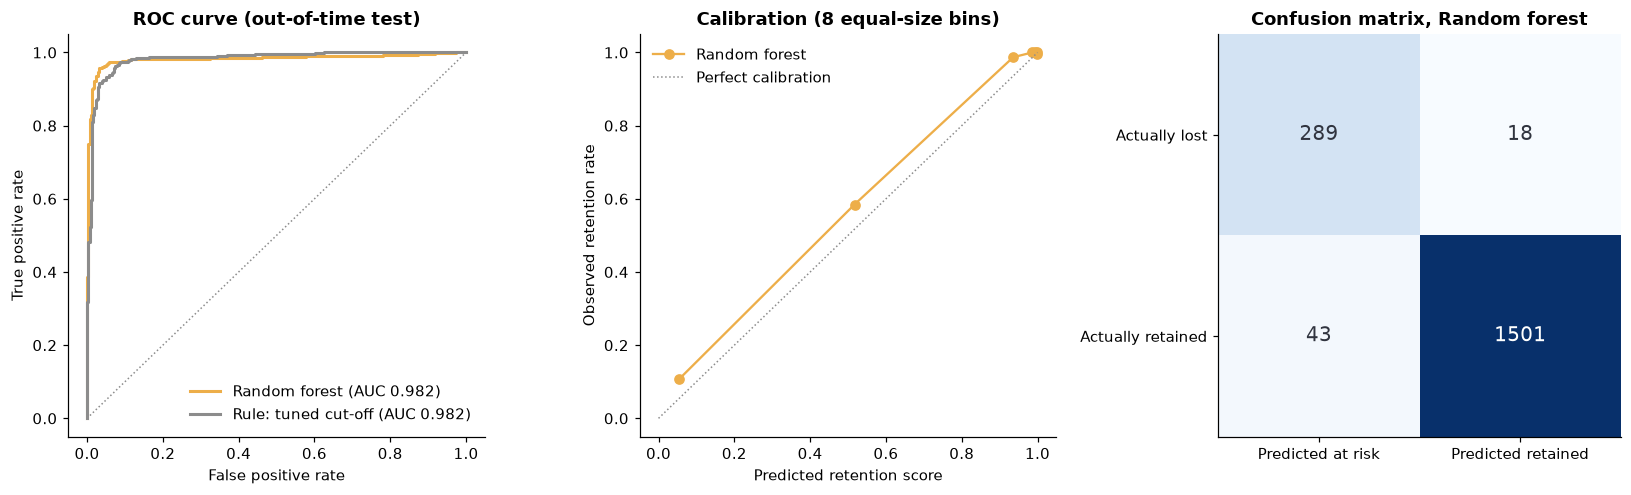

In [12]:
# The model is chosen on cross-validation, never on the test set.
best_name = cv_results.loc[["Logistic regression", "Random forest", "Gradient boosting"], ("roc_auc", "mean")].idxmax()
best_model = fitted_models[best_name]
print(f"Model chosen by grouped CV: {best_name}; tuned rule cut-off = "
      f"{np.expm1(fitted_models['Rule: tuned cut-off'].cutoff_):.1f} players")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for name, color in [(best_name, COLORS["accent"]), ("Rule: tuned cut-off", COLORS["neutral"])]:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {test_results.loc[name, 'roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=COLORS["neutral"], ls=":", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (out-of-time test)")
axes[0].legend(frameon=False, loc="lower right")

prob_true, prob_pred = calibration_curve(y_test, test_scores[best_name], n_bins=8, strategy="quantile")
axes[1].plot(prob_pred, prob_true, marker="o", color=COLORS["accent"], label=best_name)
axes[1].plot([0, 1], [0, 1], color=COLORS["neutral"], ls=":", lw=1, label="Perfect calibration")
axes[1].set(xlabel="Predicted retention score", ylabel="Observed retention rate", title="Calibration (8 equal-size bins)")
axes[1].legend(frameon=False)

matrix = confusion_matrix(y_test, labels_for(best_name, test_scores[best_name]), labels=[0, 1])
axes[2].imshow(matrix, cmap="Blues")
for (i, j), value in np.ndenumerate(matrix):
    axes[2].text(j, i, f"{value}", ha="center", va="center", fontsize=13,
                 color="white" if value > matrix.max() / 2 else COLORS["dark"])
axes[2].set_xticks([0, 1], ["Predicted at risk", "Predicted retained"])
axes[2].set_yticks([0, 1], ["Actually lost", "Actually retained"])
axes[2].set_title(f"Confusion matrix, {best_name}")
fig.tight_layout()
save(fig, "fig04_roc_calibration_confusion")
plt.show()

## 5. Does Twitch add anything? Feature-group ablation

The same model type (the best one above) is refitted with different feature groups. Each set is scored in grouped CV and on the out-of-time test.

In [13]:
ABLATION_SETS = {
    "Metadata only": META_FEATURES,
    "Twitch only": TWITCH_FEATURES,
    "Metadata + Twitch": META_FEATURES + TWITCH_FEATURES,
    "Steam only": STEAM_FEATURES,
    "Metadata + Steam": META_FEATURES + STEAM_FEATURES,
    "Metadata + Steam + Twitch": ALL_FEATURES,
}
ablation_rows = []
for set_name, columns in ABLATION_SETS.items():
    cv_auc = []
    for fit_idx, val_idx in cv.split(train, y_train, groups=train["group"]):
        model = clone(make_model(best_name)).fit(train.iloc[fit_idx][columns], y_train[fit_idx])
        cv_auc.append(roc_auc_score(y_train[val_idx], model.predict_proba(train.iloc[val_idx][columns])[:, 1]))
    model = clone(make_model(best_name)).fit(train[columns], y_train)
    scores = model.predict_proba(test[columns])[:, 1]
    low, high = bootstrap_ci(y_test, scores, (scores >= 0.5).astype(int), n_boot=500)
    ablation_rows.append({"feature_set": set_name, "n_features": len(columns), "cv_auc_mean": np.mean(cv_auc),
                          "cv_auc_std": np.std(cv_auc), "test_auc": roc_auc_score(y_test, scores),
                          "test_auc_low": low["roc_auc"], "test_auc_high": high["roc_auc"],
                          "test_balanced_accuracy": balanced_accuracy_score(y_test, (scores >= 0.5).astype(int))})
ablation = pd.DataFrame(ablation_rows).set_index("feature_set")
display(ablation.round(3))

,n_features,cv_auc_mean,cv_auc_std,test_auc,test_auc_low,test_auc_high,test_balanced_accuracy
feature_set,,,,,,,
Metadata only,42,0.948,0.018,0.919,0.897,0.938,0.837
Twitch only,7,0.946,0.035,0.966,0.955,0.975,0.934
Metadata + Twitch,49,0.980,0.007,0.973,0.964,0.981,0.886
Steam only,8,0.988,0.009,0.982,0.975,0.988,0.953
Metadata + Steam,50,0.990,0.007,0.982,0.973,0.988,0.950
Metadata + Steam + Twitch,57,0.991,0.007,0.982,0.975,0.988,0.957


Steam activity alone reaches the full model's test AUC (0.982). Twitch alone is surprisingly strong (0.966), better than metadata alone (0.919), because Twitch attention mirrors how many people play. Once Steam numbers are known, Twitch adds nothing measurable (next cell).

AUC gain from adding Twitch: +0.0002 (95% CI -0.0012 to +0.0023)
Saved reports/figures/fig05_ablation.png


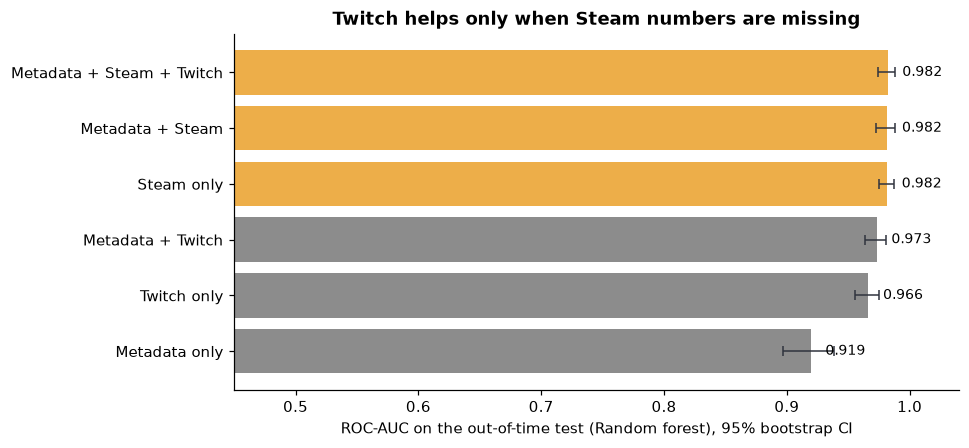

In [14]:
# Paired bootstrap: how much does adding Twitch to Metadata + Steam change test AUC?
with_twitch = clone(make_model(best_name)).fit(train[ALL_FEATURES], y_train).predict_proba(test[ALL_FEATURES])[:, 1]
without_twitch = clone(make_model(best_name)).fit(train[META_FEATURES + STEAM_FEATURES], y_train).predict_proba(test[META_FEATURES + STEAM_FEATURES])[:, 1]
rng = np.random.default_rng(RANDOM_STATE)
deltas = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test[idx].min() != y_test[idx].max():
        deltas.append(roc_auc_score(y_test[idx], with_twitch[idx]) - roc_auc_score(y_test[idx], without_twitch[idx]))
twitch_delta = (roc_auc_score(y_test, with_twitch) - roc_auc_score(y_test, without_twitch), *np.quantile(deltas, [0.025, 0.975]))
print(f"AUC gain from adding Twitch: {twitch_delta[0]:+.4f} (95% CI {twitch_delta[1]:+.4f} to {twitch_delta[2]:+.4f})")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
order = ablation.sort_values("test_auc").index
y = np.arange(len(order))
bar_colors = [COLORS["accent"] if "Steam" in name else COLORS["neutral"] for name in order]
ax.barh(y, ablation.loc[order, "test_auc"], color=bar_colors)
ax.errorbar(ablation.loc[order, "test_auc"], y,
            xerr=[ablation.loc[order, "test_auc"] - ablation.loc[order, "test_auc_low"],
                  ablation.loc[order, "test_auc_high"] - ablation.loc[order, "test_auc"]],
            fmt="none", ecolor=COLORS["dark"], capsize=3, lw=1)
for yi, value in zip(y, ablation.loc[order, "test_auc"]):
    ax.text(value + 0.012, yi, f"{value:.3f}", va="center", fontsize=9)
ax.set_yticks(y, order)
ax.set_xlim(0.45, 1.04)
ax.set_xlabel(f"ROC-AUC on the out-of-time test ({best_name}), 95% bootstrap CI")
ax.set_title("Twitch helps only when Steam numbers are missing")
save(fig, "fig05_ablation")
plt.show()

## 6. Which signals matter? Grouped permutation importance

Many features are near-duplicates (mean vs. minimum players, viewers vs. watch time). Shuffling one of them alone understates its group, because its twin still carries the information. So whole **feature groups** are shuffled together, then the most important single features are shown. Scoring: drop in out-of-time ROC-AUC, 20 repeats.

,auc_drop,std
group,,
Metadata,0.0015,0.0012
Steam activity,0.2194,0.0112
Twitch,0.0007,0.0010
Genres + tags,0.0011,0.0007


,auc_drop,std
feature,,
log_early_min,0.0128,0.0020
log_early_mean,0.0056,0.0014
low_day_share,0.0027,0.0005
trend_log_per_30d,0.0009,0.0002
tag_indie,0.0008,0.0004
twitch_viewers_per_player,0.0007,0.0008
weekend_uplift,0.0006,0.0003
freetoplay,0.0004,0.0002
twitch_mapped,0.0004,0.0002


Saved reports/figures/fig06_importance.png


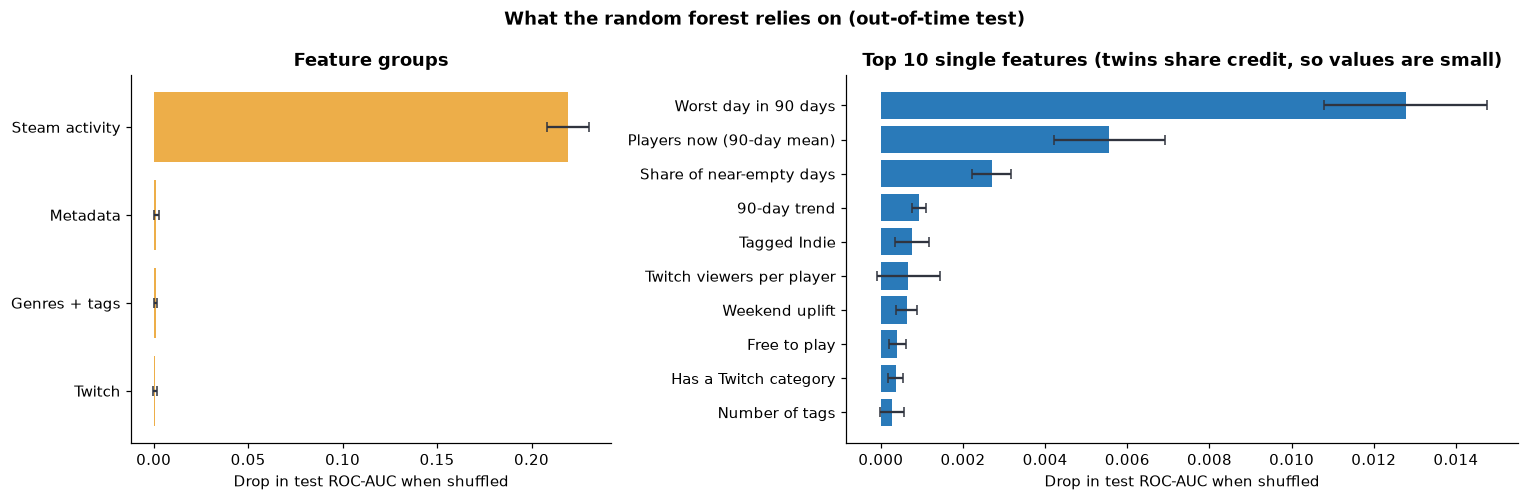

In [15]:
def permutation_auc_drop(model, frame, y, columns_to_shuffle, columns, n_repeats=20, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(frame[columns])[:, 1])
    drops = []
    for _ in range(n_repeats):
        shuffled = frame[columns].copy()
        order = rng.permutation(len(frame))
        shuffled[columns_to_shuffle] = shuffled[columns_to_shuffle].to_numpy()[order]
        drops.append(base - roc_auc_score(y, model.predict_proba(shuffled)[:, 1]))
    return np.mean(drops), np.std(drops)


group_importance = pd.DataFrame(
    [(group, *permutation_auc_drop(best_model, test, y_test, cols, ALL_FEATURES)) for group, cols in
     {**FEATURE_GROUPS, "Genres + tags": GENRE_COLUMNS + TAG_COLUMNS}.items()],
    columns=["group", "auc_drop", "std"]).set_index("group")
single_importance = pd.DataFrame(
    [(feature, *permutation_auc_drop(best_model, test, y_test, [feature], ALL_FEATURES, n_repeats=10)) for feature in ALL_FEATURES],
    columns=["feature", "auc_drop", "std"]).set_index("feature").sort_values("auc_drop", ascending=False)
display(group_importance.round(4))
display(single_importance.head(12).round(4))

# Interpretation (see the printed tables): shuffling all Steam-activity features costs ~0.22 AUC, while every other group costs < 0.005.
# The single most useful signal is the *worst day* in the 90-day window (the floor of the player base), ahead of the average.
FEATURE_LABELS = {
    "log_early_mean": "Players now (90-day mean)", "log_early_min": "Worst day in 90 days", "low_day_share": "Share of near-empty days",
    "trend_log_per_30d": "90-day trend", "last_vs_first_month": "Last vs first month", "volatility": "Day-to-day volatility",
    "log_peak_to_mean": "Peak-to-mean ratio", "weekend_uplift": "Weekend uplift", "age_years": "Game age",
    "log_twitch_avg_viewers": "Twitch avg viewers", "log_twitch_view_minutes": "Twitch watch time",
    "twitch_viewers_per_player": "Twitch viewers per player", "log_twitch_peak_viewers": "Twitch peak viewers",
    "n_languages": "Supported languages", "n_packages": "Store packages", "log_publisher_catalog": "Publisher catalogue size",
    "n_tags": "Number of tags", "freetoplay": "Free to play", "log_twitch_avg_channels": "Twitch channels",
    "twitch_mapped": "Has a Twitch category", "tag_indie": "Tagged Indie", "tag_casual": "Tagged Casual",
    "genre_massively_multiplayer": "Genre: MMO", "tag_multiplayer": "Tagged Multiplayer", "genre_early_access": "Genre: Early Access",
}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
g = group_importance.sort_values("auc_drop")
axes[0].barh(g.index, g["auc_drop"], xerr=g["std"], color=COLORS["accent"], ecolor=COLORS["dark"], capsize=3)
axes[0].set_title("Feature groups")
axes[0].set_xlabel("Drop in test ROC-AUC when shuffled")
s = single_importance.head(10).iloc[::-1]
axes[1].barh([FEATURE_LABELS.get(f, f) for f in s.index], s["auc_drop"], xerr=s["std"], color=COLORS["retained"],
             ecolor=COLORS["dark"], capsize=3)
axes[1].set_title("Top 10 single features (twins share credit, so values are small)")
axes[1].set_xlabel("Drop in test ROC-AUC when shuffled")
fig.suptitle(f"What the {best_name.lower()} relies on (out-of-time test)", fontweight="bold")
fig.tight_layout()
save(fig, "fig06_importance")
plt.show()

## 7. Robustness checks

### 7a. Retention threshold

"10 players" is a business choice. The full pipeline is rerun for other cut-offs.

,test_retention_rate,at_risk_games,rule_auc,model_auc,model_balanced_accuracy
threshold,,,,,
1,0.921,147,0.975,0.971,0.933
5,0.874,234,0.973,0.973,0.963
10,0.834,307,0.982,0.982,0.957
25,0.729,502,0.984,0.984,0.946
50,0.565,805,0.981,0.978,0.929
100,0.397,1117,0.987,0.984,0.939


Saved reports/figures/fig07_threshold_sensitivity.png


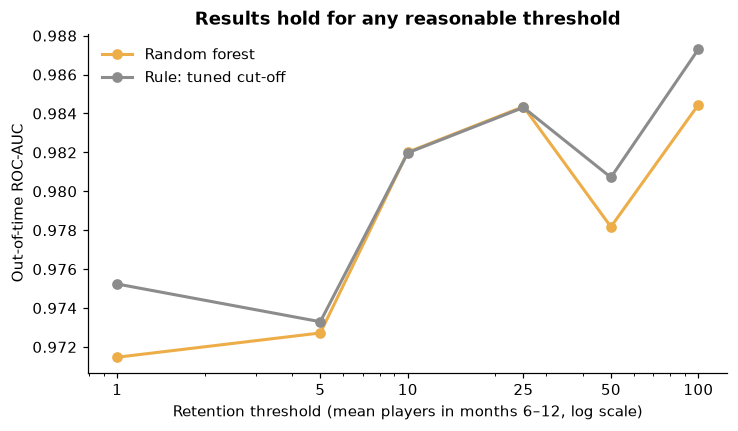

In [16]:
sensitivity_rows = []
for threshold in [1, 5, 10, 25, 50, 100]:
    y_fit = train["future_mean"].ge(threshold).astype(int).to_numpy()
    y_eval = test["future_mean"].ge(threshold).astype(int).to_numpy()
    persistence = make_model("Rule: tuned cut-off").fit(train[["early_mean"]], y_fit)
    full = clone(make_model(best_name)).fit(train[ALL_FEATURES], y_fit)
    p_scores = persistence.predict_proba(test[["early_mean"]])[:, 1]
    f_scores = full.predict_proba(test[ALL_FEATURES])[:, 1]
    sensitivity_rows.append({
        "threshold": threshold, "test_retention_rate": y_eval.mean(), "at_risk_games": int((1 - y_eval).sum()),
        "rule_auc": roc_auc_score(y_eval, p_scores), "model_auc": roc_auc_score(y_eval, f_scores),
        "model_balanced_accuracy": balanced_accuracy_score(y_eval, (f_scores >= 0.5).astype(int)),
    })
sensitivity = pd.DataFrame(sensitivity_rows).set_index("threshold")
display(sensitivity.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(sensitivity.index, sensitivity["model_auc"], marker="o", color=COLORS["accent"], lw=2, label=best_name)
ax.plot(sensitivity.index, sensitivity["rule_auc"], marker="o", color=COLORS["neutral"], lw=2, label="Rule: tuned cut-off")
ax.set_xscale("log")
ax.set_xticks(sensitivity.index, [str(t) for t in sensitivity.index])
ax.set(xlabel="Retention threshold (mean players in months 6–12, log scale)", ylabel="Out-of-time ROC-AUC",
       title="Results hold for any reasonable threshold")
ax.legend(frameon=False)
save(fig, "fig07_threshold_sensitivity")
plt.show()

Model and rule rank games almost identically at every threshold from 1 to 100 players (AUC 0.97–0.99), and the model's balanced accuracy stays at 0.93–0.96. The conclusions do not hinge on the choice of 10.

### 7b. A different period: the 2020 lockdown

Training on both 2018 origins and predicting from Aug 2019 means the outcome window is **Jan–Jul 2020**, when Steam usage jumped during COVID-19 lockdowns. This is a deliberately unfavourable test of whether the model survives a shift in the market.

In [17]:
covid = datasets["test_covid"]
train_both = pd.concat([datasets["train"], datasets["train_2"]])
y_covid = covid["retained"].to_numpy()
covid_rows = []
for name in ["Always retained", "Rule: players ≥ 10", "Rule: tuned cut-off", best_name]:
    fitted = make_model(name).fit(train_both[MODEL_FEATURES[name]], train_both["retained"]) if name in MODEL_FEATURES else None
    scores = scores_for(name, fitted, covid)
    covid_rows.append({"model": name, **metrics(y_covid, scores, labels_for(name, scores))})
covid_results = pd.DataFrame(covid_rows).set_index("model")
print(f"2020 test: {len(covid):,} games, {1 - y_covid.mean():.1%} not retained "
      f"(vs {1 - y_test.mean():.1%} in the pre-COVID test)")
display(covid_results.round(3))

2020 test: 1,851 games, 13.8% not retained (vs 16.6% in the pre-COVID test)


,roc_auc,balanced_accuracy,at_risk_precision,at_risk_recall,at_risk_avg_precision
model,,,,,
Always retained,0.500,0.500,0.000,0.000,0.138
Rule: players ≥ 10,0.967,0.935,0.731,0.925,0.803
Rule: tuned cut-off,0.967,0.872,0.399,0.980,0.803
Random forest,0.969,0.948,0.639,0.984,0.751


During the lockdown period fewer games faded (13.8% vs 16.6%). The model still edges out the fixed rule (balanced accuracy 0.948 vs 0.935; AUC 0.969 vs 0.967), so it survives a market shock. Precision for the at-risk class fell (0.64), because some games the model expected to fade were rescued by the lockdown boom.

### 7c. Young games

The use case is strongest for new releases, but only **79 games** were released 0–45 days before tracking began. Out-of-fold scores from the grouped CV (Section 4) show how the model does on exactly those games, and a decay curve shows how young and mature games differ.

Young games: 77 (released ≤45 days before 14 Dec 2017), 16% not retained


,roc_auc,balanced_accuracy,at_risk_precision,at_risk_recall,at_risk_avg_precision
model,,,,,
Rule: players ≥ 10,0.896,0.625,1.000,0.250,0.765
Rule: tuned cut-off,0.896,0.783,0.429,0.750,0.765
Random forest,0.888,0.784,0.875,0.583,0.783


Saved reports/figures/fig08_young_vs_mature_decay.png


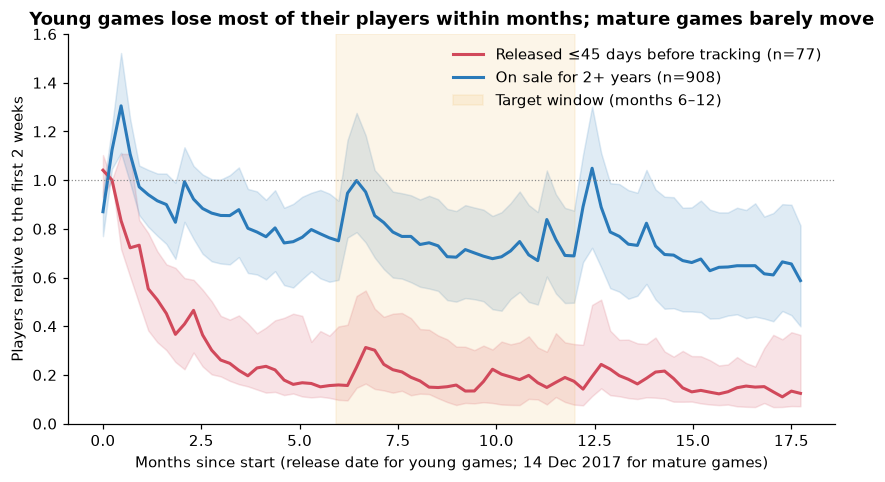

In [18]:
young_mask = train["age_years"].between(0, 45 / 365.25) & train["early_access"].eq(0)
young = train[young_mask]
y_young = young["retained"].to_numpy()
young_rows = []
for name in ["Rule: players ≥ 10", "Rule: tuned cut-off", best_name]:
    scores = oof_scores[name][young_mask.to_numpy()]
    young_rows.append({"model": name, **metrics(y_young, scores, labels_for(name, scores))})
young_results = pd.DataFrame(young_rows).set_index("model")
print(f"Young games: {len(young)} (released ≤45 days before 14 Dec 2017), {1 - y_young.mean():.0%} not retained")
display(young_results.round(3))


# Interpretation: on these 77 young games (12 of them lost) the model is no better than the rule (AUC 0.887 vs 0.896).
# It was trained mostly on mature games, whose player counts move slowly. A launch-stage model would need launch-stage training data.

def relative_curve(appids, start_dates, horizon=540):
    """Daily players relative to each game's first 14 tracked days, median and IQR across games."""
    frame = panel[panel["appid"].isin(appids)].merge(start_dates.rename("start"), left_on="appid", right_index=True)
    frame["day"] = (frame["date"] - frame["start"]).dt.days
    frame = frame[frame["day"].between(0, horizon)]
    base = frame[frame["day"] < 14].groupby("appid")["mean_player_count"].mean()
    frame["relative"] = frame["mean_player_count"] / frame["appid"].map(base).clip(lower=1)
    weekly = frame.assign(week=frame["day"] // 7).groupby(["week", "appid"])["relative"].mean().groupby("week")
    return weekly.median(), weekly.quantile(0.25), weekly.quantile(0.75)


mature = train[train["age_years"] >= 2]
curves = {
    f"Released ≤45 days before tracking (n={len(young)})": (young.index, young["releasedate"], COLORS["at_risk"]),
    f"On sale for 2+ years (n={len(mature)})": (mature.index, pd.Series(ORIGINS["train"], index=mature.index), COLORS["retained"]),
}
fig, ax = plt.subplots(figsize=(9, 4.6))
for label, (appids, starts, color) in curves.items():
    median, q1, q3 = relative_curve(appids, starts)
    ax.plot(median.index * 7 / 30.4, median, color=color, lw=2, label=label)
    ax.fill_between(median.index * 7 / 30.4, q1, q3, color=color, alpha=0.15)
ax.axhline(1, color=COLORS["neutral"], lw=0.8, ls=":")
ax.axvspan(TARGET_START / 30.4, TARGET_END / 30.4, color=COLORS["accent"], alpha=0.12, label="Target window (months 6–12)")
ax.set(xlabel="Months since start (release date for young games; 14 Dec 2017 for mature games)",
       ylabel="Players relative to the first 2 weeks", title="Young games lose most of their players within months; mature games barely move")
ax.set_ylim(0, 1.6)
ax.legend(frameon=False, loc="upper right")
save(fig, "fig08_young_vs_mature_decay")
plt.show()

The decay curve is the clearest picture of why launch-stage prediction is a different problem. Games released just before tracking lost a median ~80% of their players within five months. Mature games drift down slowly, apart from the Steam summer (month 6) and winter (month 12) sale spikes.

## 8. Forecasting the number of future players (regression)

Some users want an expected audience rather than a yes/no. The model predicts log(1 + future mean players). Errors are reported in **relative** terms, because an error of 26 players means very different things for a game with 30 players and one with 30,000. The old R² of 0.95 was computed on raw counts, where a handful of huge games dominate it.

In [19]:
y_reg_train, y_reg_test = np.log1p(train["future_mean"]), np.log1p(test["future_mean"])
regressors = {
    "Persistence (future = today)": None,
    "Linear regression": Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", LinearRegression())]),
    "Random forest": Pipeline([("impute", SimpleImputer(strategy="median")), ("model", RandomForestRegressor(
        n_estimators=500, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE))]),
}
regression_rows = []
for name, model in regressors.items():
    predictions = test["log_early_mean"].to_numpy() if model is None else model.fit(train[ALL_FEATURES], y_reg_train).predict(test[ALL_FEATURES])
    ratio = np.expm1(predictions).clip(min=0) / test["future_mean"].clip(lower=1)
    regression_rows.append({
        "model": name,
        "MAE_log": np.mean(np.abs(predictions - y_reg_test)),
        "R2_log": 1 - np.sum((predictions - y_reg_test) ** 2) / np.sum((y_reg_test - y_reg_test.mean()) ** 2),
        "median_abs_pct_error": np.median(np.abs(ratio - 1)),
        "share_within_25pct": np.mean(np.abs(ratio - 1) <= 0.25),
    })
regression_results = pd.DataFrame(regression_rows).set_index("model")
display(regression_results.round(3))

,MAE_log,R2_log,median_abs_pct_error,share_within_25pct
model,,,,
Persistence (future = today),0.314,0.937,0.208,0.560
Linear regression,0.337,0.931,0.227,0.538
Random forest,0.321,0.940,0.217,0.557


For forecasting the *number* of future players, machine learning does **not** beat persistence ("next year ≈ today"): the median error is 21% for both. We therefore pitch the classifier, not the regression.

## 9. Deliverables

### 9a. Backtest: do the risk tiers mean anything?

Each test game gets a risk tier from its predicted retention score. The table shows what actually happened to each tier. This number belongs on the slides: it tells a publisher how much to trust a "high risk" label.

,games,actually_lost,share_lost,median_players_now,share_of_all_lost_games
risk_tier,,,,,
High risk,332,289,0.870,1.939,0.941
Medium risk,114,12,0.105,18.217,0.039
Low risk,1405,6,0.004,114.489,0.020


Saved reports/figures/fig09_risk_tiers_backtest.png


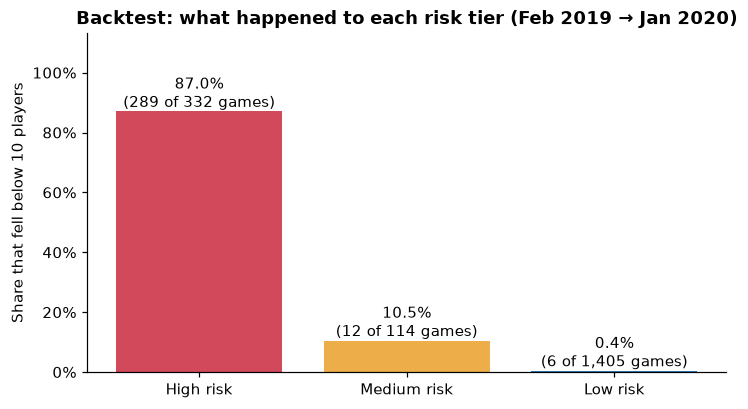

In [20]:
TIER_BINS, TIER_LABELS = [-np.inf, 0.5, 0.8, np.inf], ["High risk", "Medium risk", "Low risk"]
backtest = test[["name", "publisher", "early_mean", "future_mean", "retained"]].copy()
backtest["retention_score"] = test_scores[best_name]
backtest["risk_tier"] = pd.cut(backtest["retention_score"], TIER_BINS, labels=TIER_LABELS)
tier_summary = backtest.groupby("risk_tier", observed=False).agg(
    games=("name", "size"), actually_lost=("retained", lambda v: int((1 - v).sum())),
    share_lost=("retained", lambda v: 1 - v.mean()), median_players_now=("early_mean", "median"))
tier_summary["share_of_all_lost_games"] = tier_summary["actually_lost"] / (1 - backtest["retained"]).sum()
display(tier_summary.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(tier_summary))
bars = ax.bar(x, tier_summary["share_lost"], color=[COLORS["at_risk"], COLORS["accent"], COLORS["retained"]])
for xi, (share, games, lost) in enumerate(zip(tier_summary["share_lost"], tier_summary["games"], tier_summary["actually_lost"])):
    ax.text(xi, share + 0.015, f"{share:.1%}\n({lost} of {games:,} games)", ha="center", fontsize=10)
ax.set_xticks(x, tier_summary.index)
ax.set_ylim(0, max(tier_summary["share_lost"]) * 1.3)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set(ylabel="Share that fell below 10 players", title="Backtest: what happened to each risk tier (Feb 2019 → Jan 2020)")
save(fig, "fig09_risk_tiers_backtest")
plt.show()

The tiers are sharp. 87% of "high risk" games really did fall below 10 players, and that tier holds 94% of all lost games. Only 6 of 1,405 "low risk" games (0.4%) were lost. The 114 "medium risk" games (10.5% lost) are the shortlist where a human review adds the most.

Saved reports/figures/fig10_example_trajectories.png


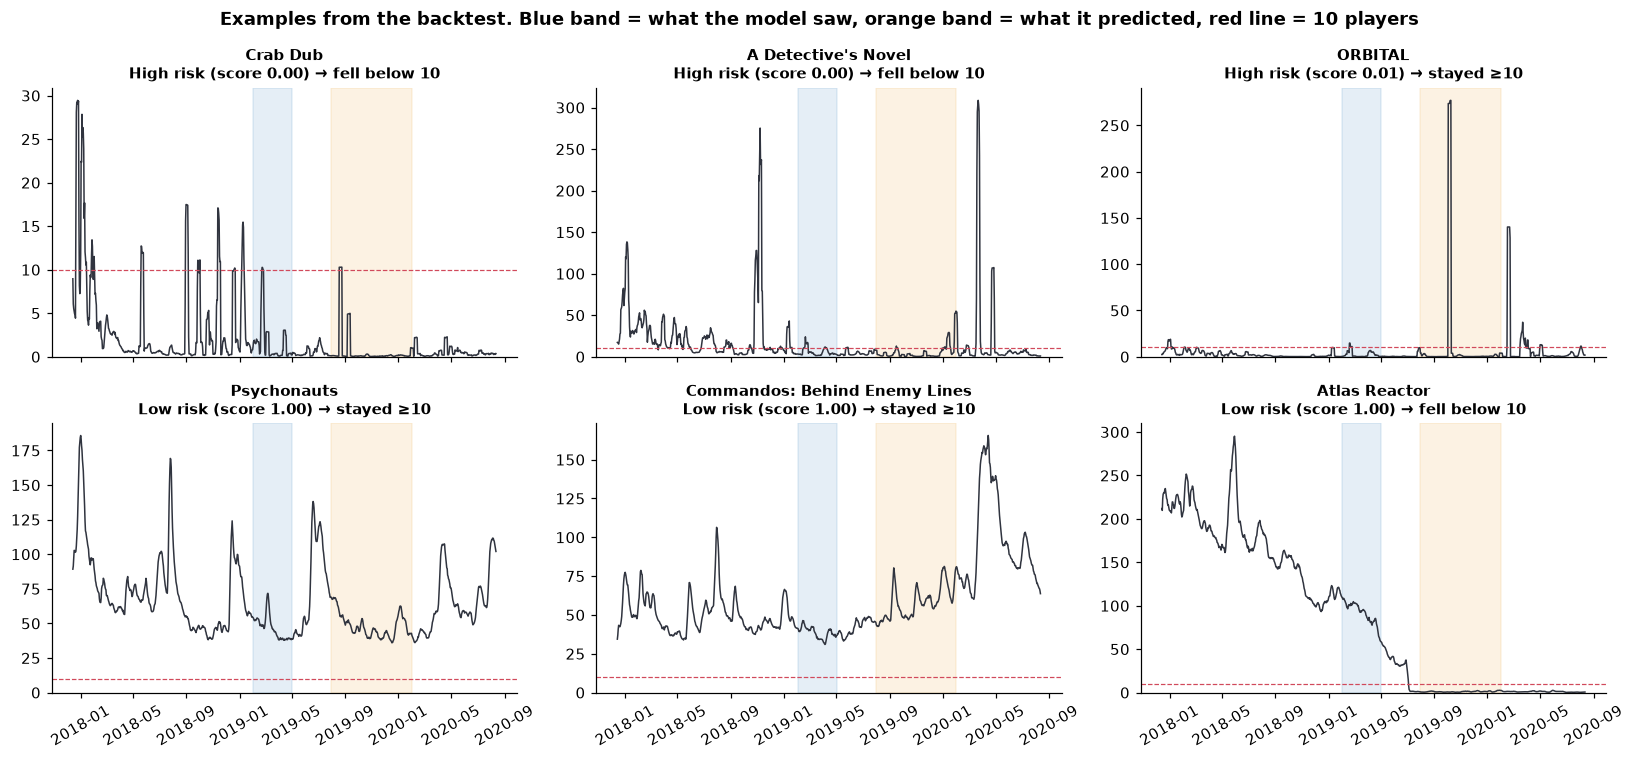

In [21]:
examples = pd.concat([
    backtest[(backtest["risk_tier"] == "High risk") & (backtest["retained"] == 0)].nsmallest(2, "retention_score"),
    backtest[(backtest["risk_tier"] == "High risk") & (backtest["retained"] == 1)].nsmallest(1, "retention_score"),
    backtest[(backtest["risk_tier"] == "Low risk") & backtest["early_mean"].between(10, 60)].nlargest(2, "retention_score"),
    backtest[(backtest["risk_tier"] == "Low risk") & (backtest["retained"] == 0)].nlargest(1, "retention_score"),
])
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
origin = ORIGINS["test"]
for ax, (appid, row) in zip(axes.ravel(), examples.iterrows()):
    history = panel[panel["appid"] == appid].set_index("date")["mean_player_count"].rolling(7, min_periods=1).mean()
    ax.plot(history.index, history, color=COLORS["dark"], lw=1)
    ax.axvspan(origin, origin + pd.Timedelta(days=FEATURE_DAYS), color=COLORS["retained"], alpha=0.12)
    ax.axvspan(origin + pd.Timedelta(days=TARGET_START), origin + pd.Timedelta(days=TARGET_END), color=COLORS["accent"], alpha=0.15)
    ax.axhline(THRESHOLD, color=COLORS["at_risk"], ls="--", lw=0.8)
    outcome = "stayed ≥10" if row["retained"] else "fell below 10"
    ax.set_title(f"{row['name'][:32]}\n{row['risk_tier']} (score {row['retention_score']:.2f}) → {outcome}", fontsize=10)
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", labelrotation=30)
fig.suptitle("Examples from the backtest. Blue band = what the model saw, orange band = what it predicted, red line = 10 players",
             fontweight="bold")
fig.tight_layout()
save(fig, "fig10_example_trajectories")
plt.show()

### 9b. Forward forecast as of the last day of data

The deployable version is trained on every origin whose outcome is already known (Dec 2017, Jun 2018, Feb 2019, Aug 2019). It scores all games on their **latest 90 days** (15 May – 12 Aug 2020), which predicts Nov 2020 – May 2021. Those outcomes are not in the data, so this table is a forecast, not a result.

In [22]:
forecast_origin = DATA_END - pd.Timedelta(days=FEATURE_DAYS - 1)
latest = build_dataset(forecast_origin, labelled=False)
all_labelled = pd.concat(datasets.values())
final_model = clone(make_model(best_name)).fit(all_labelled[ALL_FEATURES], all_labelled["retained"])
forecast = latest[["name", "publisher", "early_mean"]].rename(columns={"early_mean": "mean_players_last_90_days"})
forecast["retention_score"] = final_model.predict_proba(latest[ALL_FEATURES])[:, 1]
forecast["risk_tier"] = pd.cut(forecast["retention_score"], TIER_BINS, labels=TIER_LABELS)
forecast = forecast.sort_values("retention_score")
print(f"Forecast origin {forecast_origin.date()}: {len(forecast):,} games scored")
display(forecast["risk_tier"].value_counts().reindex(TIER_LABELS))
display(forecast.head(10).round(3))

REPORT_DIR.mkdir(exist_ok=True)
backtest.sort_values("retention_score").round(4).to_csv(REPORT_DIR / "risk_table_backtest_2019.csv", index_label="appid")
forecast.round(4).to_csv(REPORT_DIR / "risk_forecast_2020-08.csv", index_label="appid")
print("Wrote reports/risk_table_backtest_2019.csv and reports/risk_forecast_2020-08.csv")

Forecast origin 2020-05-15: 1,851 games scored


risk_tier
High risk       349
Medium risk      62
Low risk       1440
Name: count, dtype: int64

,name,publisher,mean_players_last_90_days,retention_score,risk_tier
appid,,,,,
383800,Close Order,Raconteur Games,0.023,0.006,High risk
567780,Satellite Repairman,Nuno Donato,0.009,0.007,High risk
659460,RiotZ,Triple Rush Games,0.017,0.008,High risk
512770,IACTURA,Merlin Beer,0.016,0.011,High risk
533180,Campfire: One of Us Is the Killer,Abstractive Works,0.002,0.011,High risk
620940,Invisibox,Retrific,0.971,0.011,High risk
467120,Rising Runner,Magicbane,0.023,0.012,High risk
622920,P-Walker's Simulation,BrainStrainStudios,0.019,0.012,High risk
454180,CrazyCars3D,Anea_Duo_Dev,0.078,0.015,High risk


Wrote reports/risk_table_backtest_2019.csv and reports/risk_forecast_2020-08.csv


## 10. Save metrics for the report

In [23]:
results = {
    "settings": {"feature_days": FEATURE_DAYS, "target_days": [TARGET_START, TARGET_END], "threshold": THRESHOLD,
                 "origins": {k: str(v.date()) for k, v in ORIGINS.items()}, "best_model": best_name},
    "coverage": coverage.astype(str).to_dict(orient="index"),
    "cv": {model: {metric: round(cv_results.loc[model, (metric, "mean")], 4) for metric in ["roc_auc", "balanced_accuracy"]}
           | {"roc_auc_std": round(cv_results.loc[model, ("roc_auc", "std")], 4)} for model in cv_results.index},
    "test": test_results.round(4).to_dict(orient="index"),
    "borderline": {"games": int(borderline.sum()), "not_retained": int((1 - y_test[borderline]).sum()),
                   **{"results": borderline_results.round(4).to_dict(orient="index")}},
    "ablation": ablation.round(4).to_dict(orient="index"),
    "twitch_auc_gain": [round(v, 4) for v in twitch_delta],
    "group_importance": group_importance.round(4).to_dict(orient="index"),
    "top_features": single_importance.head(10).round(4).to_dict(orient="index"),
    "threshold_sensitivity": sensitivity.round(4).to_dict(orient="index"),
    "covid_test": covid_results.round(4).to_dict(orient="index"),
    "young_games": {"games": len(young), "not_retained": int((1 - y_young).sum()), "results": young_results.round(4).to_dict(orient="index")},
    "regression": regression_results.round(4).to_dict(orient="index"),
    "risk_tiers_backtest": tier_summary.round(4).to_dict(orient="index"),
    "forecast_tiers": forecast["risk_tier"].value_counts().to_dict(),
    "group_rates": pd.concat([business, twitch_rates, genre_rates]).round(4).to_dict(orient="records"),
}
(REPORT_DIR / "metrics.json").write_text(json.dumps(results, indent=2, default=str), encoding="utf-8")
print("Wrote reports/metrics.json")

Wrote reports/metrics.json


## 11. Conclusions

1. **H1 — recent Steam activity predicts retention: supported.** Steam activity carries almost all the signal. Its floor (worst day) and level matter most. The out-of-time ROC-AUC is 0.98.
2. **H2 — Twitch adds value beyond Steam: not supported.** Twitch alone is informative (AUC 0.966), but adding it to Steam features changes test AUC by +0.0002 (95% CI −0.0012 to +0.0023).
3. **H3 — retention differs by business model and genre: supported descriptively, irrelevant for prediction.** Free-to-play games retain 96% vs 86% for paid games, and Casual games only 68%. Once player counts are known, these features add < 0.005 AUC.
4. **Where ML adds value.** Over the whole catalogue, a "≥10 players today" rule ranks games as well as the model. The model wins on flagging: it catches 94% vs 87% of lost games. It also stays stable across market periods, where the rule's balanced accuracy swung from 0.69 to 0.93. On borderline games (5–50 players) it is clearly better (AUC 0.961 vs 0.931).
5. **Where it does not.** It cannot forecast audience size better than "next year ≈ today", and it does not beat the rule on freshly launched games (77 games, AUC 0.887 vs 0.896).

The full write-up is in [`reports/technical_report.md`](../reports/technical_report.md).